In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r"C:\Users\rupesh\Downloads\rohit\dataset\predictive_maintenance_v3.csv")

In [3]:
df.head()

,timestamp,machine_id,machine_type,vibration_rms,temperature_motor,current_phase_avg,pressure_level,rpm,operating_mode,hours_since_maintenance,ambient_temp,rul_hours,failure_within_24h,failure_type,estimated_repair_cost
0,2024-01-01 00:00:00,1,CNC,0.81,49.51,5.10,23.6,860.9,idle,273.80,13.9,61.00,0,none,0
1,2024-01-01 00:03:00,1,CNC,0.75,40.58,5.30,23.6,899.6,idle,273.85,10.2,60.95,0,none,0
2,2024-01-01 00:21:00,1,CNC,0.71,49.70,NaN,21.3,862.7,idle,274.15,13.6,60.65,0,none,0
3,2024-01-01 00:45:00,1,CNC,0.76,43.04,4.79,22.6,870.4,idle,274.55,13.4,60.25,0,none,0
4,2024-01-01 00:54:00,1,CNC,0.88,41.39,4.44,22.2,881.9,idle,274.70,10.8,60.10,0,none,0


In [4]:
# Basic Data Inspection


In [5]:
df.head()

,timestamp,machine_id,machine_type,vibration_rms,temperature_motor,current_phase_avg,pressure_level,rpm,operating_mode,hours_since_maintenance,ambient_temp,rul_hours,failure_within_24h,failure_type,estimated_repair_cost
0,2024-01-01 00:00:00,1,CNC,0.81,49.51,5.10,23.6,860.9,idle,273.80,13.9,61.00,0,none,0
1,2024-01-01 00:03:00,1,CNC,0.75,40.58,5.30,23.6,899.6,idle,273.85,10.2,60.95,0,none,0
2,2024-01-01 00:21:00,1,CNC,0.71,49.70,NaN,21.3,862.7,idle,274.15,13.6,60.65,0,none,0
3,2024-01-01 00:45:00,1,CNC,0.76,43.04,4.79,22.6,870.4,idle,274.55,13.4,60.25,0,none,0
4,2024-01-01 00:54:00,1,CNC,0.88,41.39,4.44,22.2,881.9,idle,274.70,10.8,60.10,0,none,0


In [6]:
df.shape

(24042, 15)

In [7]:
df.tail()

,timestamp,machine_id,machine_type,vibration_rms,temperature_motor,current_phase_avg,pressure_level,rpm,operating_mode,hours_since_maintenance,ambient_temp,rul_hours,failure_within_24h,failure_type,estimated_repair_cost
24037,2024-01-14 22:17:56,20,Robotic Arm,0.98,37.18,5.27,45.0,361.8,normal,163.43,10.2,0.5,0,none,0
24038,2024-01-14 22:41:56,20,Robotic Arm,0.45,33.90,2.21,18.9,159.5,idle,163.83,11.0,0.5,0,none,0
24039,2024-01-14 22:58:56,20,Robotic Arm,0.40,29.15,2.29,19.0,159.5,idle,164.12,16.2,0.5,0,none,0
24040,2024-01-14 23:23:56,20,Robotic Arm,0.45,31.47,2.45,18.0,151.4,idle,164.53,16.7,0.5,0,none,0
24041,2024-01-14 23:52:56,20,Robotic Arm,0.44,33.73,2.25,14.8,153.4,idle,165.02,9.2,0.5,0,none,0


In [8]:
df.columns

Index(['timestamp', 'machine_id', 'machine_type', 'vibration_rms',
       'temperature_motor', 'current_phase_avg', 'pressure_level', 'rpm',
       'operating_mode', 'hours_since_maintenance', 'ambient_temp',
       'rul_hours', 'failure_within_24h', 'failure_type',
       'estimated_repair_cost'],
      dtype='object')

In [9]:
df.dtypes

timestamp                   object
machine_id                   int64
machine_type                object
vibration_rms              float64
temperature_motor          float64
current_phase_avg          float64
pressure_level             float64
rpm                        float64
operating_mode              object
hours_since_maintenance    float64
ambient_temp               float64
rul_hours                  float64
failure_within_24h           int64
failure_type                object
estimated_repair_cost        int64
dtype: object

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24042 entries, 0 to 24041
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   timestamp                24042 non-null  object 
 1   machine_id               24042 non-null  int64  
 2   machine_type             24042 non-null  object 
 3   vibration_rms            23042 non-null  float64
 4   temperature_motor        23208 non-null  float64
 5   current_phase_avg        23311 non-null  float64
 6   pressure_level           23118 non-null  float64
 7   rpm                      23509 non-null  float64
 8   operating_mode           24042 non-null  object 
 9   hours_since_maintenance  24042 non-null  float64
 10  ambient_temp             24042 non-null  float64
 11  rul_hours                24042 non-null  float64
 12  failure_within_24h       24042 non-null  int64  
 13  failure_type             24042 non-null  object 
 14  estimated_repair_cost 

In [11]:
df.isnull().sum()

timestamp                     0
machine_id                    0
machine_type                  0
vibration_rms              1000
temperature_motor           834
current_phase_avg           731
pressure_level              924
rpm                         533
operating_mode                0
hours_since_maintenance       0
ambient_temp                  0
rul_hours                     0
failure_within_24h            0
failure_type                  0
estimated_repair_cost         0
dtype: int64

In [12]:
#Separate Variables
numerical_cols = df.select_dtypes(include=np.number).columns

numerical_cols

Index(['machine_id', 'vibration_rms', 'temperature_motor', 'current_phase_avg',
       'pressure_level', 'rpm', 'hours_since_maintenance', 'ambient_temp',
       'rul_hours', 'failure_within_24h', 'estimated_repair_cost'],
      dtype='object')

In [13]:
categorical_cols = df.select_dtypes(include='object').columns

categorical_cols

Index(['timestamp', 'machine_type', 'operating_mode', 'failure_type'], dtype='object')

In [14]:
# statical summary

In [15]:
df.describe()

,machine_id,vibration_rms,temperature_motor,current_phase_avg,pressure_level,rpm,hours_since_maintenance,ambient_temp,rul_hours,failure_within_24h,estimated_repair_cost
count,24042.000000,23042.000000,23208.000000,23311.000000,23118.000000,23509.000000,24042.000000,24042.000000,24042.000000,24042.000000,24042.000000
mean,10.505033,1.623667,51.404295,8.823829,59.012233,1144.849317,172.630624,12.996398,27.812510,0.148074,608.870144
std,5.746455,1.081061,12.519279,5.366391,38.723271,912.670971,150.722469,2.883994,26.393801,0.355181,1566.793887
min,1.000000,0.350000,28.000000,2.200000,10.100000,124.100000,0.000000,8.000000,0.500000,0.000000,0.000000
25%,6.000000,0.820000,42.610000,4.630000,22.700000,489.400000,42.870000,10.500000,0.500000,0.000000,0.000000
50%,10.000000,1.270000,50.060000,6.430000,46.300000,856.000000,121.610000,13.000000,22.570000,0.000000,0.000000
75%,15.000000,2.270000,59.962500,13.120000,94.700000,1676.000000,295.575000,15.500000,46.410000,0.000000,0.000000
max,20.000000,10.000000,95.000000,35.000000,206.500000,4098.800000,575.630000,18.000000,98.340000,1.000000,7995.000000


In [16]:
#Generate a statistical summary of all numerical sensor columns.

In [17]:
sensor_cols = [
    'vibration_rms',
    'temperature_motor',
    'current_phase_avg',
    'pressure_level',
    'rpm',
    'hours_since_maintenance',
    'ambient_temp',
    'rul_hours',
    'estimated_repair_cost'
]

In [18]:
df[sensor_cols].describe()

,vibration_rms,temperature_motor,current_phase_avg,pressure_level,rpm,hours_since_maintenance,ambient_temp,rul_hours,estimated_repair_cost
count,23042.000000,23208.000000,23311.000000,23118.000000,23509.000000,24042.000000,24042.000000,24042.000000,24042.000000
mean,1.623667,51.404295,8.823829,59.012233,1144.849317,172.630624,12.996398,27.812510,608.870144
std,1.081061,12.519279,5.366391,38.723271,912.670971,150.722469,2.883994,26.393801,1566.793887
min,0.350000,28.000000,2.200000,10.100000,124.100000,0.000000,8.000000,0.500000,0.000000
25%,0.820000,42.610000,4.630000,22.700000,489.400000,42.870000,10.500000,0.500000,0.000000
50%,1.270000,50.060000,6.430000,46.300000,856.000000,121.610000,13.000000,22.570000,0.000000
75%,2.270000,59.962500,13.120000,94.700000,1676.000000,295.575000,15.500000,46.410000,0.000000
max,10.000000,95.000000,35.000000,206.500000,4098.800000,575.630000,18.000000,98.340000,7995.000000


- Business Questions

In [19]:
# Machine condition
# use aggregation function

In [20]:
#What is the average vibration level?
df['vibration_rms'].mean()

np.float64(1.6236667823973614)

In [21]:
#What is the maximum motor temperature?
df['temperature_motor'].max()

95.0

In [22]:
# average of rpm
df['rpm'].mean()

np.float64(1144.8493172827427)

In [23]:
# what is average rul
df['rul_hours'].mean()

np.float64(27.812510190499953)

In [24]:
# what average maximum hr since maintenance
df['hours_since_maintenance'].max()

575.63

# Check Missing Values

In [25]:
df.isnull().sum()

timestamp                     0
machine_id                    0
machine_type                  0
vibration_rms              1000
temperature_motor           834
current_phase_avg           731
pressure_level              924
rpm                         533
operating_mode                0
hours_since_maintenance       0
ambient_temp                  0
rul_hours                     0
failure_within_24h            0
failure_type                  0
estimated_repair_cost         0
dtype: int64

In [26]:
missing_percentage = df.isnull().mean() * 100

missing_percentage.sort_values(ascending=False)

vibration_rms              4.159388
pressure_level             3.843274
temperature_motor          3.468929
current_phase_avg          3.040512
rpm                        2.216954
timestamp                  0.000000
machine_id                 0.000000
machine_type               0.000000
operating_mode             0.000000
hours_since_maintenance    0.000000
ambient_temp               0.000000
rul_hours                  0.000000
failure_within_24h         0.000000
failure_type               0.000000
estimated_repair_cost      0.000000
dtype: float64

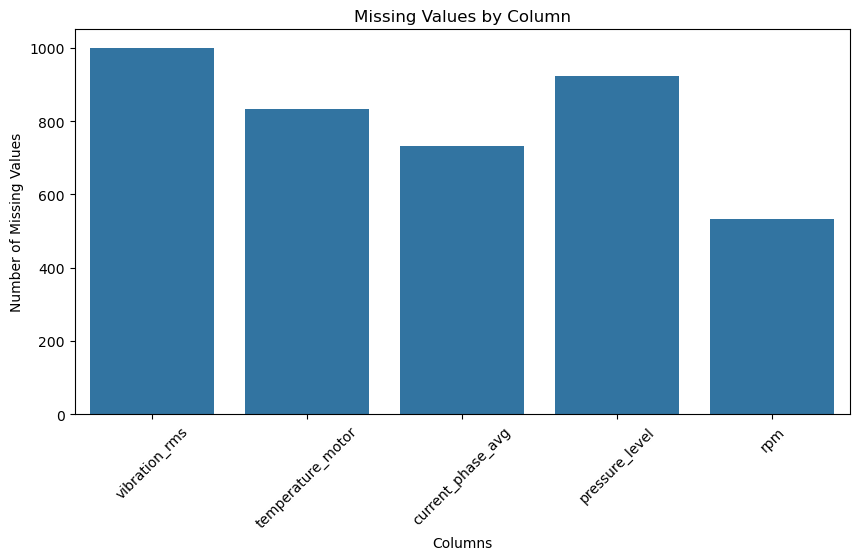

In [27]:
#Visualize missing values
missing = df.isnull().sum()

missing = missing[missing > 0]

plt.figure(figsize=(10, 5))

sns.barplot(
    x=missing.index,
    y=missing.values
)

plt.xticks(rotation=45)
plt.xlabel('Columns')
plt.ylabel('Number of Missing Values')
plt.title('Missing Values by Column')

plt.show()

In [28]:
df['vibration_rms'] = df['vibration_rms'].fillna(
    df['vibration_rms'].median()
)

In [29]:
df.dtypes

timestamp                   object
machine_id                   int64
machine_type                object
vibration_rms              float64
temperature_motor          float64
current_phase_avg          float64
pressure_level             float64
rpm                        float64
operating_mode              object
hours_since_maintenance    float64
ambient_temp               float64
rul_hours                  float64
failure_within_24h           int64
failure_type                object
estimated_repair_cost        int64
dtype: object

In [30]:
df['temperature_motor'] =df['temperature_motor'].fillna(
    df['temperature_motor'].median()
)

In [31]:
df.isnull().sum()

timestamp                    0
machine_id                   0
machine_type                 0
vibration_rms                0
temperature_motor            0
current_phase_avg          731
pressure_level             924
rpm                        533
operating_mode               0
hours_since_maintenance      0
ambient_temp                 0
rul_hours                    0
failure_within_24h           0
failure_type                 0
estimated_repair_cost        0
dtype: int64

In [32]:
df['current_phase_avg'] = df['current_phase_avg'].fillna( df['current_phase_avg'].median())

In [33]:
df['pressure_level'] = df['pressure_level'] .fillna(df['pressure_level'] .median())

In [34]:
df['rpm'] = df['rpm'].fillna(df['rpm'].median())

In [35]:
df.isnull().sum()

timestamp                  0
machine_id                 0
machine_type               0
vibration_rms              0
temperature_motor          0
current_phase_avg          0
pressure_level             0
rpm                        0
operating_mode             0
hours_since_maintenance    0
ambient_temp               0
rul_hours                  0
failure_within_24h         0
failure_type               0
estimated_repair_cost      0
dtype: int64

**Duplicate Records Analysis.**

In [36]:
df.duplicated().sum()

np.int64(0)

In [37]:
df.duplicated(
    subset=['machine_id', 'timestamp']
).sum()

np.int64(0)

In [38]:
# Data Validation / Invalid Values.

In [39]:
df[['vibration_rms',
    'temperature_motor',
    'current_phase_avg',
    'pressure_level',
    'rpm',
    'hours_since_maintenance',
    'ambient_temp',
    'rul_hours',
    'estimated_repair_cost']].min()

vibration_rms                0.35
temperature_motor           28.00
current_phase_avg            2.20
pressure_level              10.10
rpm                        124.10
hours_since_maintenance      0.00
ambient_temp                 8.00
rul_hours                    0.50
estimated_repair_cost        0.00
dtype: float64

In [40]:
# check all columns together
numeric_cols = df.select_dtypes(include=np.number).columns

negative_values = (df[numeric_cols] < 0).sum()

negative_values

machine_id                 0
vibration_rms              0
temperature_motor          0
current_phase_avg          0
pressure_level             0
rpm                        0
hours_since_maintenance    0
ambient_temp               0
rul_hours                  0
failure_within_24h         0
estimated_repair_cost      0
dtype: int64

In [41]:
#Check categorical values
df['machine_type'].value_counts()

machine_type
Pump           6114
Robotic Arm    6003
Compressor     5988
CNC            5937
Name: count, dtype: int64

In [42]:
df['operating_mode'].value_counts()

operating_mode
normal    11632
idle      10862
peak       1548
Name: count, dtype: int64

In [43]:
df['failure_type'].value_counts()

failure_type
none              20482
bearing            1117
motor_overheat     1060
hydraulic           728
electrical          655
Name: count, dtype: int64

In [44]:
# Check timestamp validity
df['timestamp'].min()

'2024-01-01 00:00:00'

In [45]:
df['timestamp'].max()


'2024-01-14 23:59:38'

- logical relationships → Heatmap is useful for correlation

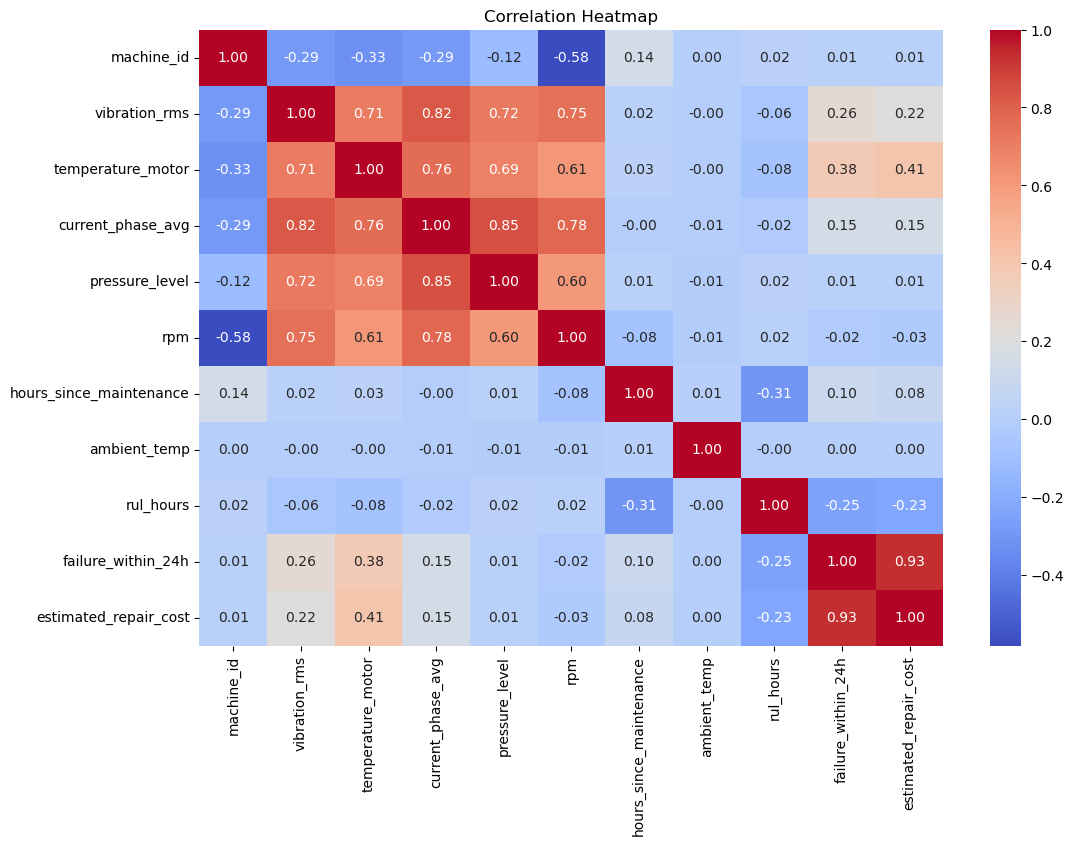

In [46]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(12, 8))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

 # Outlier Detection

In [47]:
sensor_cols = [
    'vibration_rms',
    'temperature_motor',
    'current_phase_avg',
    'pressure_level',
    'rpm',
    'hours_since_maintenance',
    'ambient_temp',
    'rul_hours',
    'estimated_repair_cost'
]

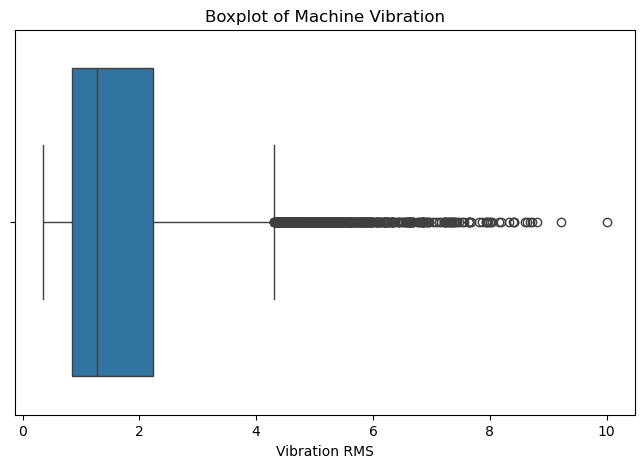

In [48]:
#Visualize outliers using Boxplot
plt.figure(figsize=(8, 5))

sns.boxplot(x=df['vibration_rms'])

plt.title('Boxplot of Machine Vibration')
plt.xlabel('Vibration RMS')

plt.show()

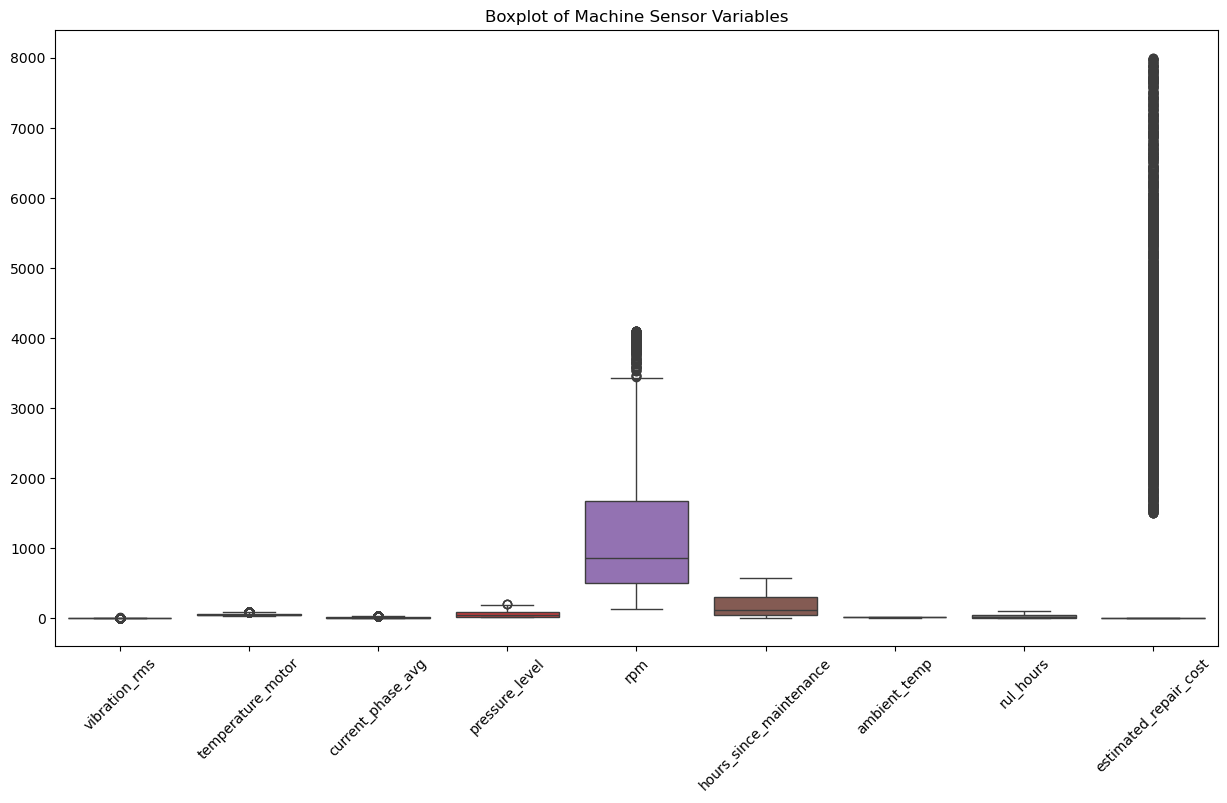

In [49]:
#Create boxplots for all sensor variables
plt.figure(figsize=(15, 8))

sns.boxplot(data=df[sensor_cols])

plt.xticks(rotation=45)
plt.title('Boxplot of Machine Sensor Variables')

plt.show()

**Use IQR Method**

In [50]:
outlier_summary = {}

for col in sensor_cols:
    
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    count = (
        (df[col] < lower) |
        (df[col] > upper)
    ).sum()
    
    outlier_summary[col] = count

outlier_summary

{'vibration_rms': np.int64(523),
 'temperature_motor': np.int64(270),
 'current_phase_avg': np.int64(181),
 'pressure_level': np.int64(3),
 'rpm': np.int64(374),
 'hours_since_maintenance': np.int64(0),
 'ambient_temp': np.int64(0),
 'rul_hours': np.int64(0),
 'estimated_repair_cost': np.int64(3560)}

In [51]:
outlier_df = pd.DataFrame(
    outlier_summary.items(),
    columns=['Column', 'Outlier_Count']
)

outlier_df

,Column,Outlier_Count
0,vibration_rms,523
1,temperature_motor,270
2,current_phase_avg,181
3,pressure_level,3
4,rpm,374
5,hours_since_maintenance,0
6,ambient_temp,0
7,rul_hours,0
8,estimated_repair_cost,3560


In [52]:
# Calculate Outlier Percentage
outlier_df['Outlier_Percentage'] = (
    outlier_df['Outlier_Count'] / len(df)
) * 100

In [53]:
outlier_df.sort_values(
    'Outlier_Percentage',
    ascending=False
)

,Column,Outlier_Count,Outlier_Percentage
8,estimated_repair_cost,3560,14.807420
0,vibration_rms,523,2.175360
4,rpm,374,1.555611
1,temperature_motor,270,1.123035
2,current_phase_avg,181,0.752849
3,pressure_level,3,0.012478
5,hours_since_maintenance,0,0.000000
6,ambient_temp,0,0.000000
7,rul_hours,0,0.000000


In [54]:
for col in sensor_cols:
    
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower = Q1 - (1.5 * IQR)
    upper = Q3 + (1.5 * IQR)
    df[col] = df[col].clip(lower,upper)

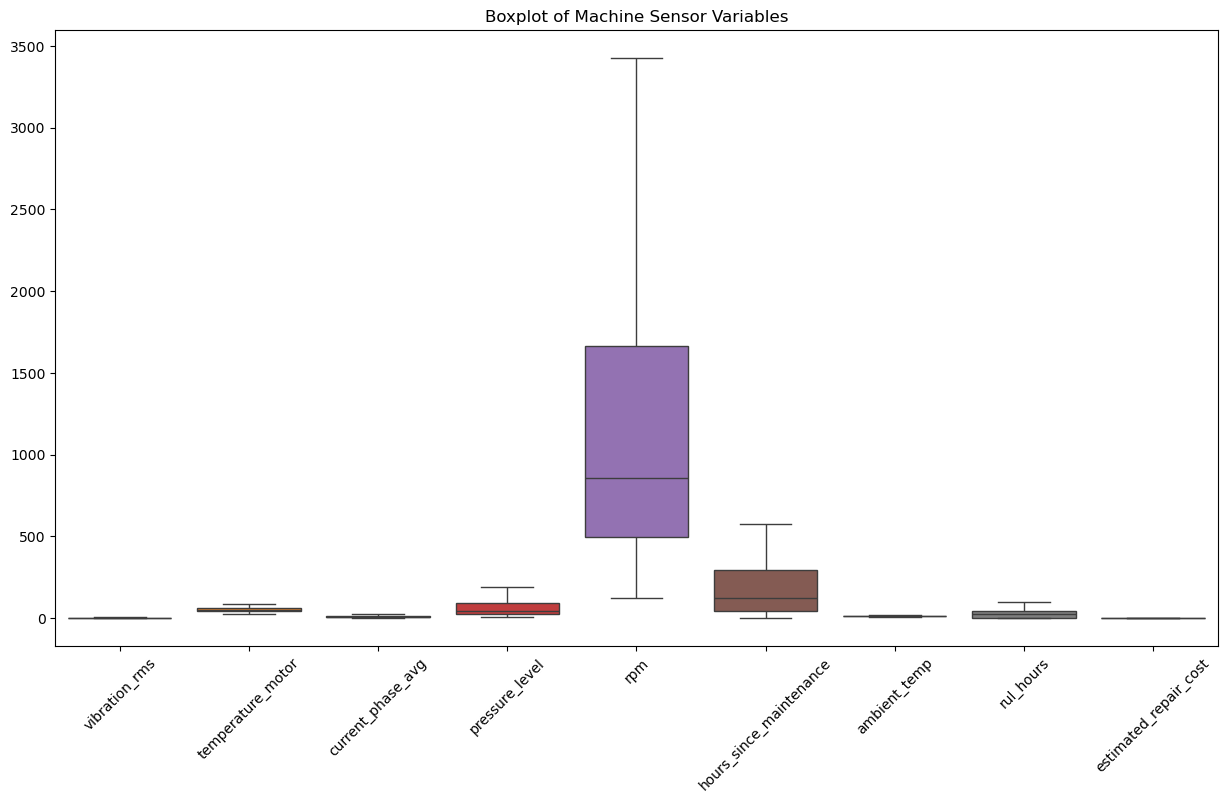

In [55]:
plt.figure(figsize=(15, 8))

sns.boxplot(data=df[sensor_cols])

plt.xticks(rotation=45)
plt.title('Boxplot of Machine Sensor Variables')

plt.show()

- I used boxplots and the IQR method to identify potential outliers in sensor variables such as vibration, motor temperature, current, pressure, and RPM. However, I did not automatically remove them because extreme sensor values can represent genuine machine-health problems. I first investigated whether the outlier was a sensor/data-quality issue or an actual abnormal machine condition." 

# Univariate Analysis

- How vibration is distributed
- How motor temperature is distributed
- Machine operating speed
- Maintenance history
- RUL distribution
- Repair-cost distribution
- Failure-type distribution

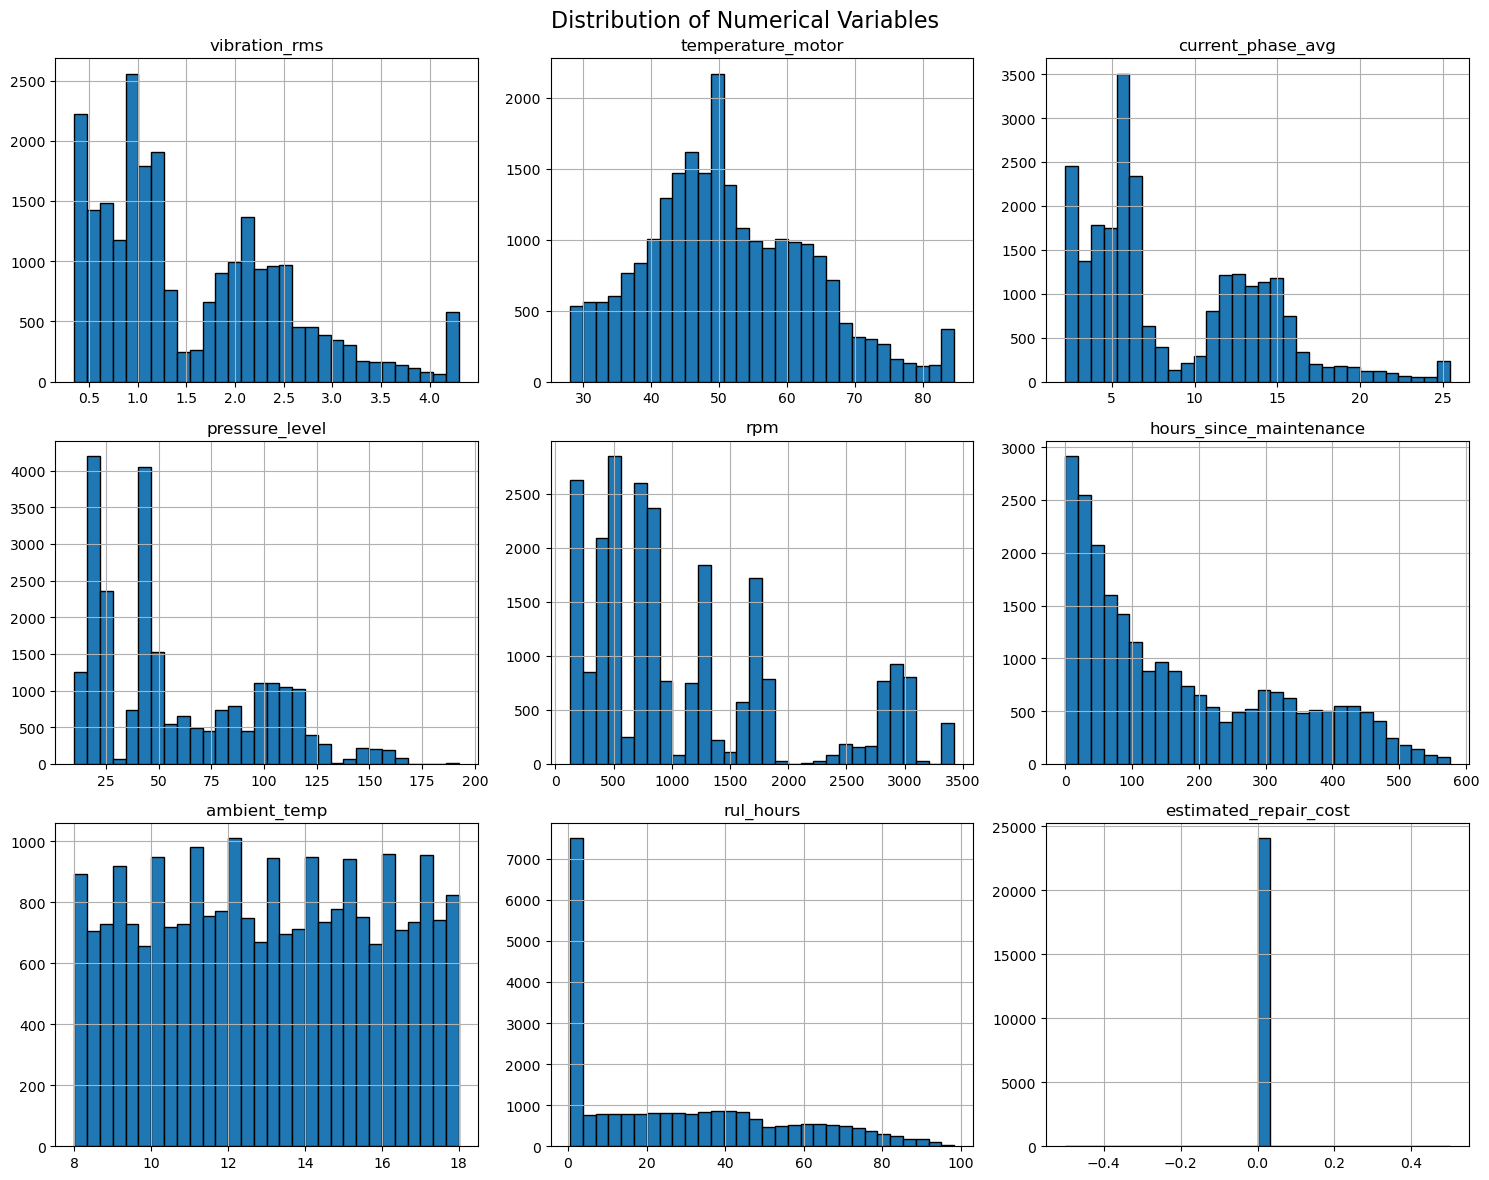

In [56]:
numerical_cols = [
    'vibration_rms',
    'temperature_motor',
    'current_phase_avg',
    'pressure_level',
    'rpm',
    'hours_since_maintenance',
    'ambient_temp',
    'rul_hours',
    'estimated_repair_cost'
]

df[numerical_cols].hist(
    figsize=(15, 12),
    bins=30,
    edgecolor='black'
)

plt.suptitle('Distribution of Numerical Variables', fontsize=16)
plt.tight_layout()
plt.show()

In [57]:
# Calculate Failure Percentage
df['failure_within_24h'].value_counts(normalize=True) * 100

failure_within_24h
0    85.19258
1    14.80742
Name: proportion, dtype: float64

<Axes: >

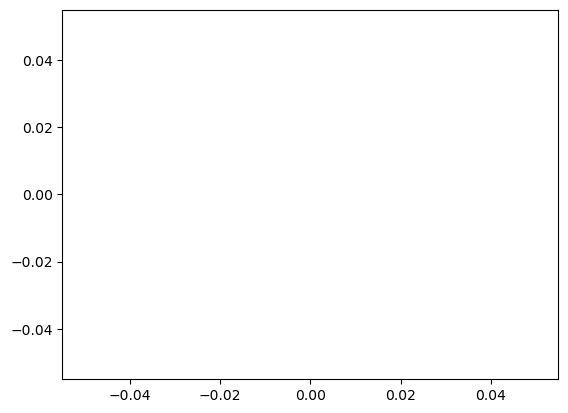

In [58]:
#Numerical variable
sns.histplot()

# catogrical data
sns.countplot()

- Univariate analysis was performed to understand the individual distributions of machine sensor, maintenance, failure, and cost variables. Histograms and KDE plots were used for numerical variables such as vibration, motor temperature, RPM, RUL, and maintenance hours. Count plots were used for categorical variables such as machine type, operating mode, and failure type. The analysis helped identify the central tendency, distribution patterns, skewness, and potential abnormal observations in the dataset.

# Bivariate Analysis

- Does higher vibration relate to machine failure?
- Does higher temperature relate to failure?
- Does maintenance delay affect RUL?
- Which machine type has the highest failure rate?
- Does operating mode affect machine condition?

In [59]:
df.head()

,timestamp,machine_id,machine_type,vibration_rms,temperature_motor,current_phase_avg,pressure_level,rpm,operating_mode,hours_since_maintenance,ambient_temp,rul_hours,failure_within_24h,failure_type,estimated_repair_cost
0,2024-01-01 00:00:00,1,CNC,0.81,49.51,5.10,23.6,860.9,idle,273.80,13.9,61.00,0,none,0
1,2024-01-01 00:03:00,1,CNC,0.75,40.58,5.30,23.6,899.6,idle,273.85,10.2,60.95,0,none,0
2,2024-01-01 00:21:00,1,CNC,0.71,49.70,6.43,21.3,862.7,idle,274.15,13.6,60.65,0,none,0
3,2024-01-01 00:45:00,1,CNC,0.76,43.04,4.79,22.6,870.4,idle,274.55,13.4,60.25,0,none,0
4,2024-01-01 00:54:00,1,CNC,0.88,41.39,4.44,22.2,881.9,idle,274.70,10.8,60.10,0,none,0


In [60]:
df.dtypes

timestamp                   object
machine_id                   int64
machine_type                object
vibration_rms              float64
temperature_motor          float64
current_phase_avg          float64
pressure_level             float64
rpm                        float64
operating_mode              object
hours_since_maintenance    float64
ambient_temp               float64
rul_hours                  float64
failure_within_24h           int64
failure_type                object
estimated_repair_cost        int64
dtype: object

In [61]:
df['timestamp'] = pd.to_datetime (df['timestamp'])

In [62]:
df.dtypes

timestamp                  datetime64[ns]
machine_id                          int64
machine_type                       object
vibration_rms                     float64
temperature_motor                 float64
current_phase_avg                 float64
pressure_level                    float64
rpm                               float64
operating_mode                     object
hours_since_maintenance           float64
ambient_temp                      float64
rul_hours                         float64
failure_within_24h                  int64
failure_type                       object
estimated_repair_cost               int64
dtype: object

In [63]:
df['Year'] = df['timestamp'].dt.year    # also know as feature engineering  mean to add columns base on main column  orderdate
df['Monthname']=  df['timestamp'].dt.month_name()
df['Dayname'] = df['timestamp'].dt.day_name()
df['Quarter'] = df['timestamp'].dt.quarter

In [64]:
df.head()

,timestamp,machine_id,machine_type,vibration_rms,temperature_motor,current_phase_avg,pressure_level,rpm,operating_mode,hours_since_maintenance,ambient_temp,rul_hours,failure_within_24h,failure_type,estimated_repair_cost,Year,Monthname,Dayname,Quarter
0,2024-01-01 00:00:00,1,CNC,0.81,49.51,5.10,23.6,860.9,idle,273.80,13.9,61.00,0,none,0,2024,January,Monday,1
1,2024-01-01 00:03:00,1,CNC,0.75,40.58,5.30,23.6,899.6,idle,273.85,10.2,60.95,0,none,0,2024,January,Monday,1
2,2024-01-01 00:21:00,1,CNC,0.71,49.70,6.43,21.3,862.7,idle,274.15,13.6,60.65,0,none,0,2024,January,Monday,1
3,2024-01-01 00:45:00,1,CNC,0.76,43.04,4.79,22.6,870.4,idle,274.55,13.4,60.25,0,none,0,2024,January,Monday,1
4,2024-01-01 00:54:00,1,CNC,0.88,41.39,4.44,22.2,881.9,idle,274.70,10.8,60.10,0,none,0,2024,January,Monday,1


In [65]:
df.tail()

,timestamp,machine_id,machine_type,vibration_rms,temperature_motor,current_phase_avg,pressure_level,rpm,operating_mode,hours_since_maintenance,ambient_temp,rul_hours,failure_within_24h,failure_type,estimated_repair_cost,Year,Monthname,Dayname,Quarter
24037,2024-01-14 22:17:56,20,Robotic Arm,0.98,37.18,5.27,45.0,361.8,normal,163.43,10.2,0.5,0,none,0,2024,January,Sunday,1
24038,2024-01-14 22:41:56,20,Robotic Arm,0.45,33.90,2.21,18.9,159.5,idle,163.83,11.0,0.5,0,none,0,2024,January,Sunday,1
24039,2024-01-14 22:58:56,20,Robotic Arm,0.40,29.15,2.29,19.0,159.5,idle,164.12,16.2,0.5,0,none,0,2024,January,Sunday,1
24040,2024-01-14 23:23:56,20,Robotic Arm,0.45,31.47,2.45,18.0,151.4,idle,164.53,16.7,0.5,0,none,0,2024,January,Sunday,1
24041,2024-01-14 23:52:56,20,Robotic Arm,0.44,33.73,2.25,14.8,153.4,idle,165.02,9.2,0.5,0,none,0,2024,January,Sunday,1


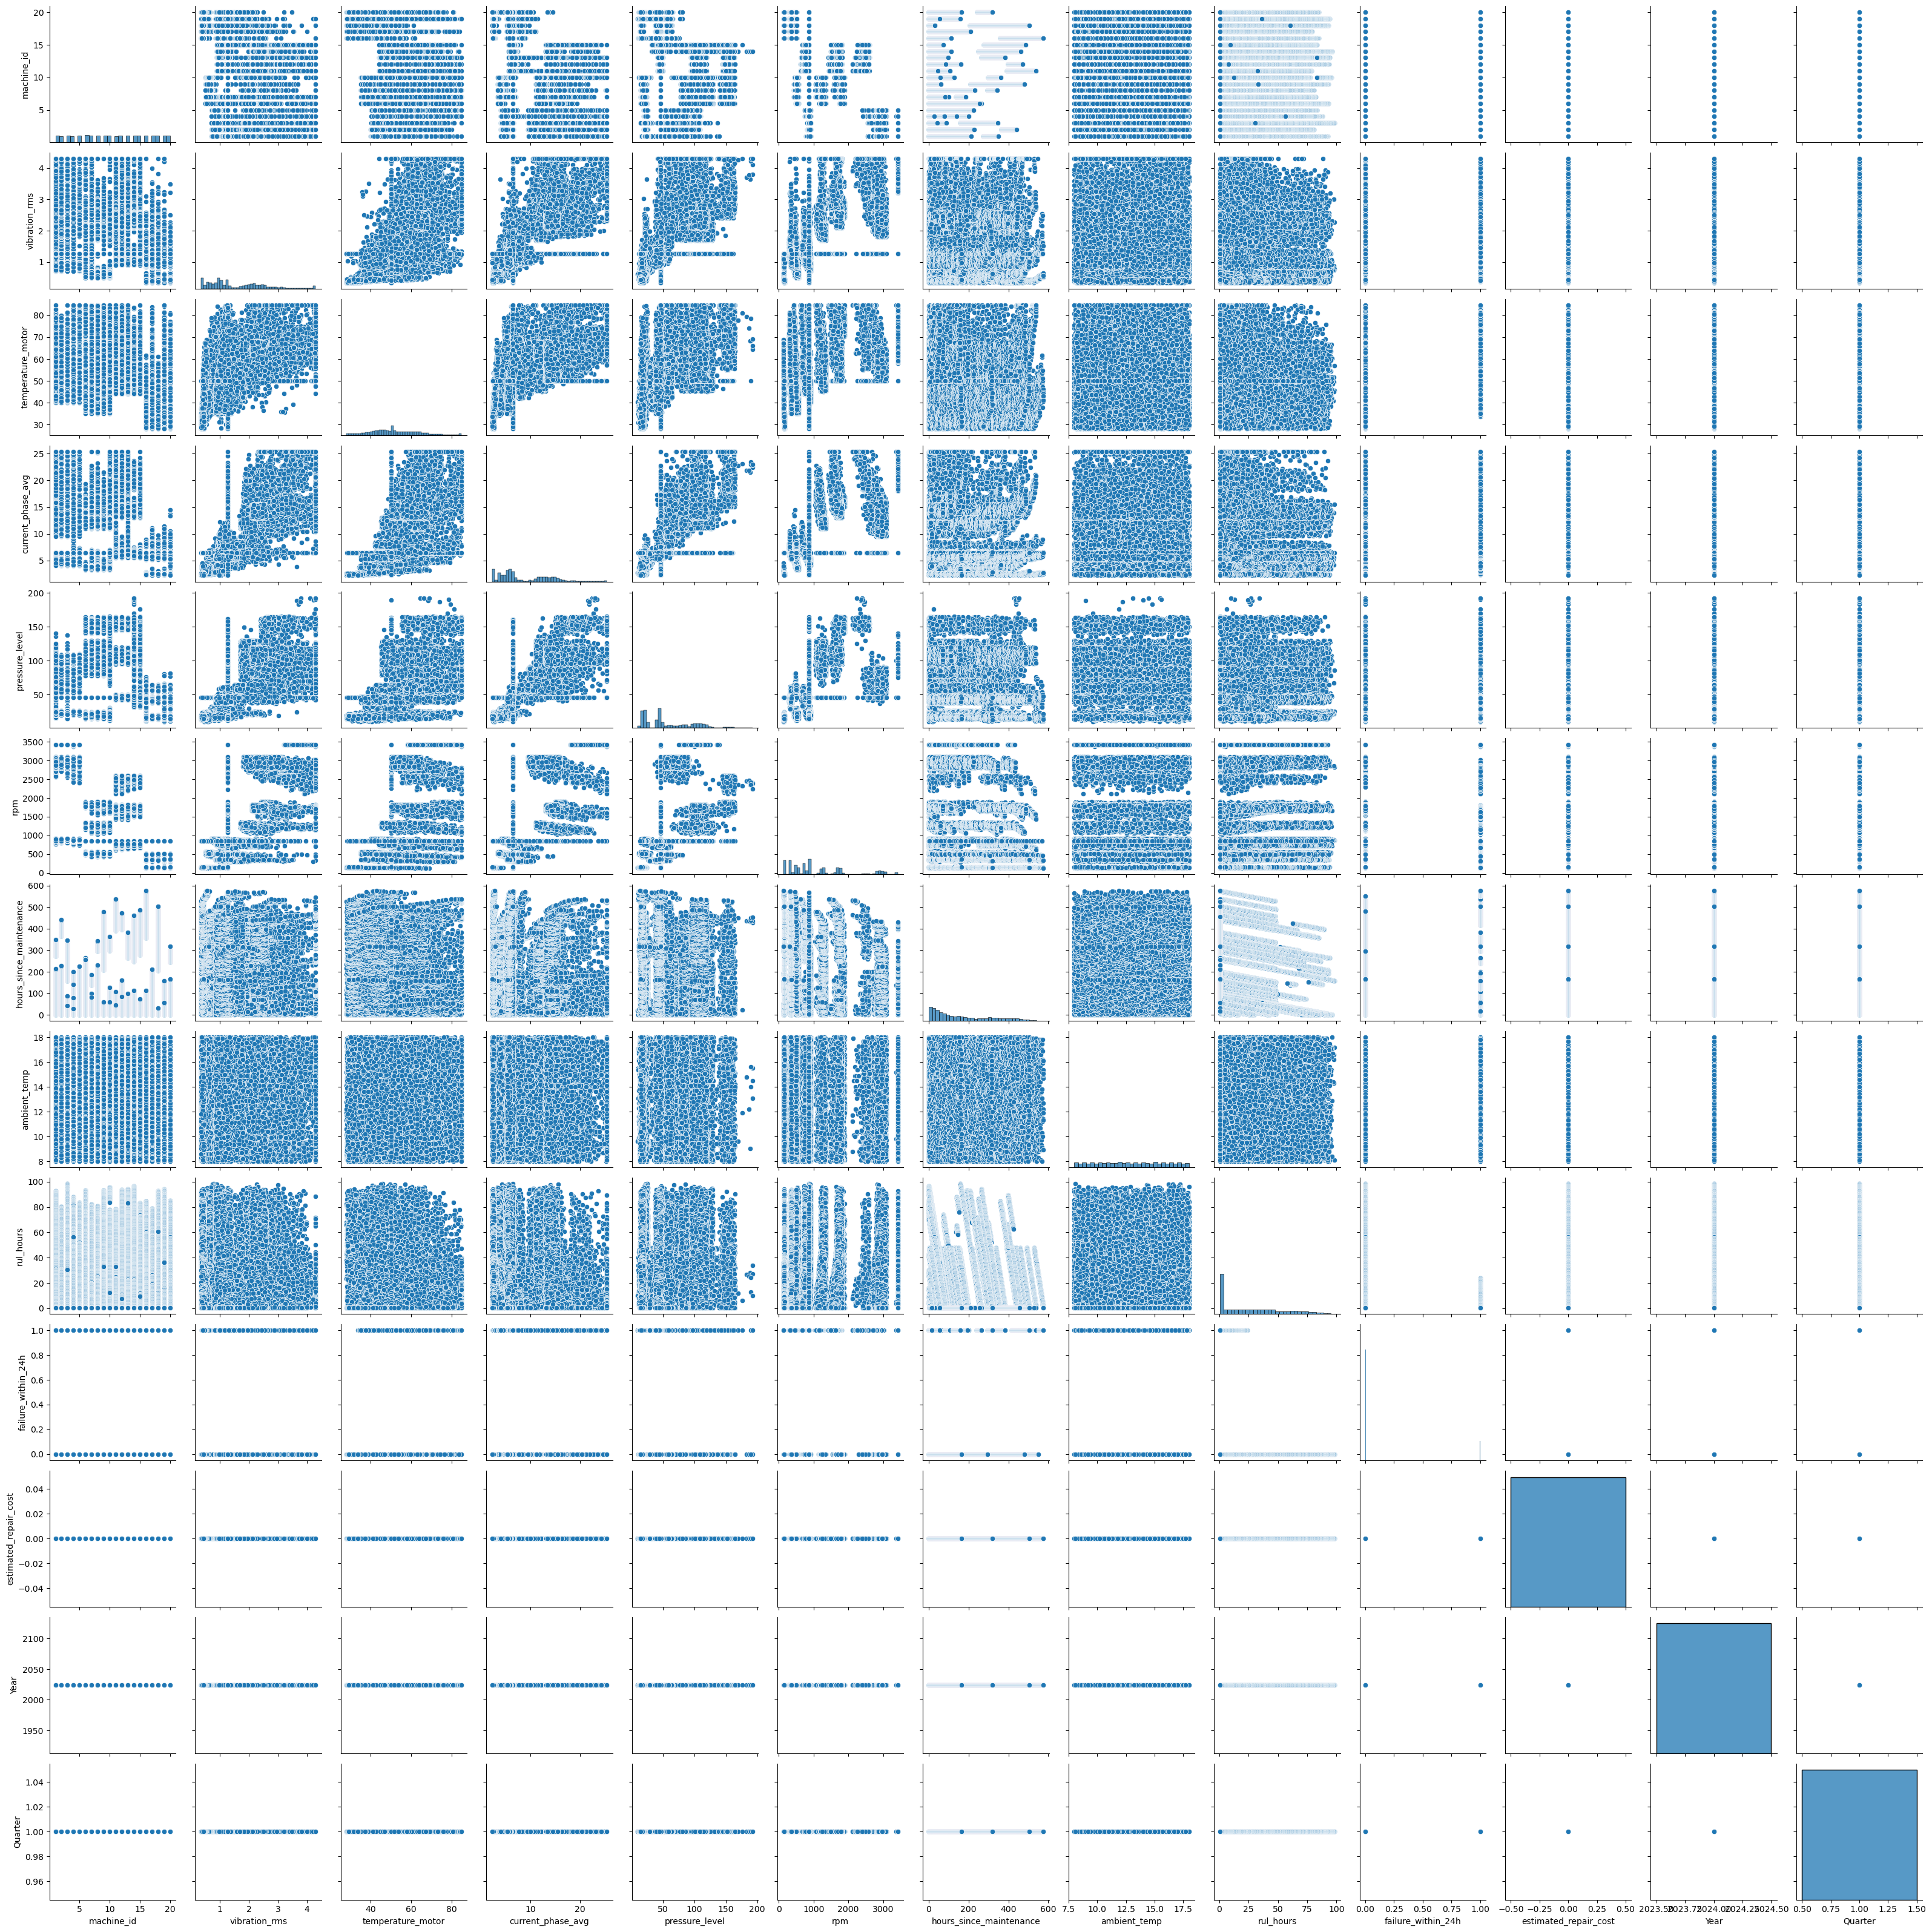

In [66]:
sns.pairplot(df)

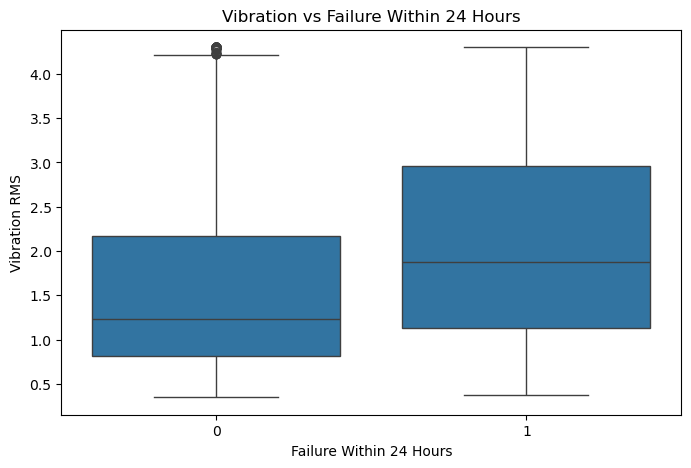

In [67]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='failure_within_24h',
    y='vibration_rms'
)

plt.title('Vibration vs Failure Within 24 Hours')
plt.xlabel('Failure Within 24 Hours')
plt.ylabel('Vibration RMS')

plt.show()


- Machines expected to fail within 24 hours tend to show higher vibration levels.

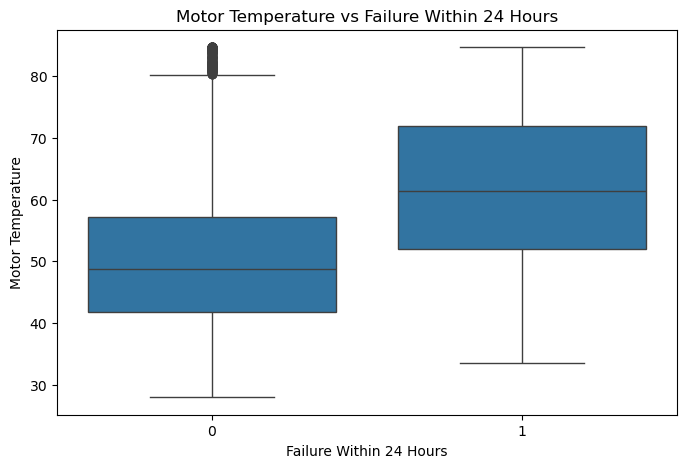

In [68]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='failure_within_24h',
    y='temperature_motor'
)

plt.title('Motor Temperature vs Failure Within 24 Hours')
plt.xlabel('Failure Within 24 Hours')
plt.ylabel('Motor Temperature')

plt.show()

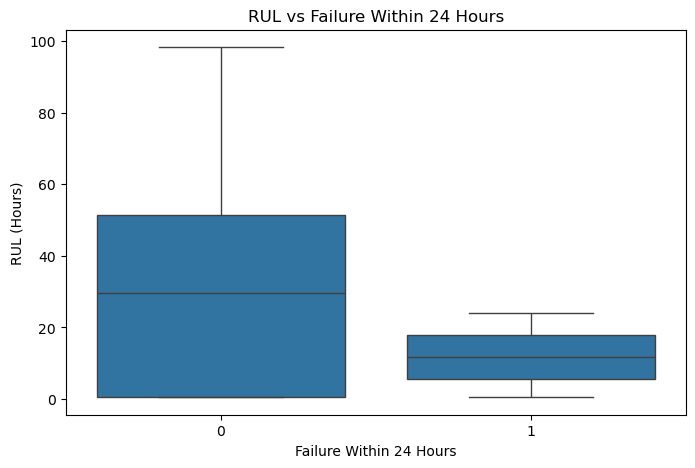

In [69]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='failure_within_24h',
    y='rul_hours'
)

plt.title('RUL vs Failure Within 24 Hours')
plt.xlabel('Failure Within 24 Hours')
plt.ylabel('RUL (Hours)')

plt.show()

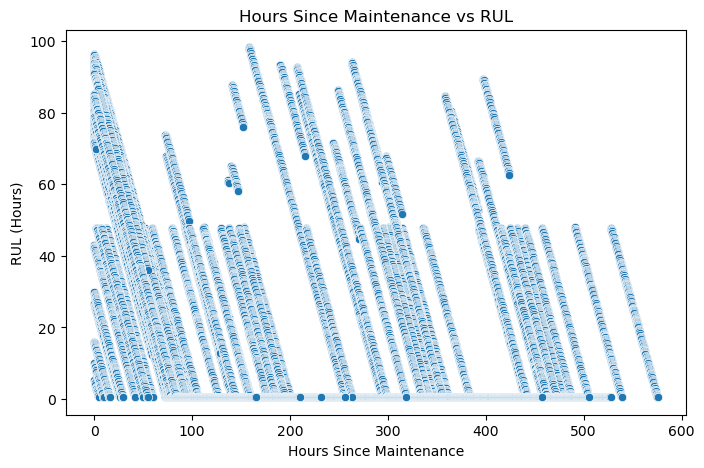

In [70]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='hours_since_maintenance',
    y='rul_hours'
)

plt.title('Hours Since Maintenance vs RUL')
plt.xlabel('Hours Since Maintenance')
plt.ylabel('RUL (Hours)')

plt.show()

In [71]:
# Failure Type vs Repair Cost
repair_cost = (
    df.groupby('failure_type')['estimated_repair_cost']
      .mean()
      .sort_values(ascending=False)
)

repair_cost

failure_type
bearing           0.0
electrical        0.0
hydraulic         0.0
motor_overheat    0.0
none              0.0
Name: estimated_repair_cost, dtype: float64

In [72]:
# Analysis — High-Risk Sensor Pattern
high_risk = df[
    (df['vibration_rms'] > df['vibration_rms'].quantile(0.75)) &
    (df['temperature_motor'] > df['temperature_motor'].quantile(0.75))
]

high_risk.shape

(3688, 19)

In [73]:
high_risk['failure_within_24h'].mean() * 100

np.float64(32.619305856832966)

- Bivariate analysis was performed to investigate relationships between machine sensor parameters, maintenance history, RUL, and failure status. Boxplots were used to compare vibration, temperature, and RUL across failure groups, while scatter plots were used to analyze relationships between maintenance hours, RUL, vibration, and temperature. Failure rates were also compared across machine types. The analysis helped identify sensor and maintenance patterns associated with increased machine failure risk.

# Failure Analysis

- How many failures occurred?
- What types of failures are common?
- Which machine types fail more?
- Which operating modes have more failures?
- What sensor conditions are associated with failure?
- What is the potential repair cost of failures? 

In [74]:
#check the disribution
df['failure_within_24h'].value_counts()

failure_within_24h
0    20482
1     3560
Name: count, dtype: int64

In [75]:
failure_count = (df['failure_within_24h'] == 1).sum()

print("Total Failures:", failure_count)

Total Failures: 3560


In [76]:
# calculate failure rate
failure_rate = df['failure_within_24h'].mean() * 100

print("Failure Rate:", failure_rate)

Failure Rate: 14.807420347724815


In [77]:
df['failure_type'].value_counts()

failure_type
none              20482
bearing            1117
motor_overheat     1060
hydraulic           728
electrical          655
Name: count, dtype: int64

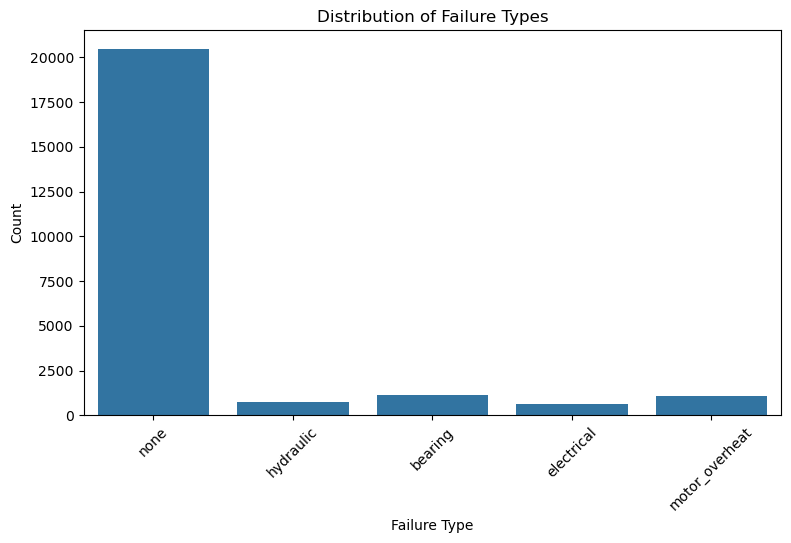

In [78]:
# visualization
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='failure_type'
)

plt.title('Distribution of Failure Types')
plt.xlabel('Failure Type')
plt.ylabel('Count')

plt.xticks(rotation=45)

plt.show()

**Failure Rate by Machine Type**

In [79]:
machine_failure_rate = (
    df.groupby('machine_type')['failure_within_24h']
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

machine_failure_rate

machine_type
Compressor     15.998664
Pump           14.932941
Robotic Arm    14.242879
CNC            14.047499
Name: failure_within_24h, dtype: float64

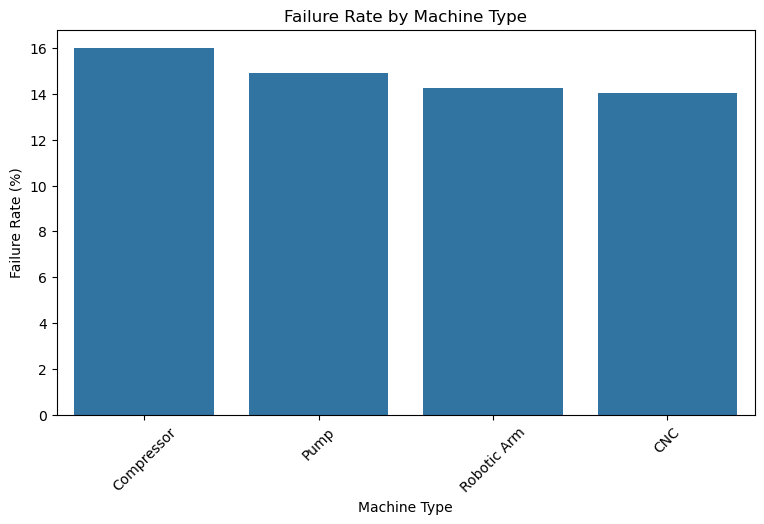

In [80]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=machine_failure_rate.index,
    y=machine_failure_rate.values
)

plt.title('Failure Rate by Machine Type')
plt.xlabel('Machine Type')
plt.ylabel('Failure Rate (%)')

plt.xticks(rotation=45)

plt.show()

- Machine types with higher failure rates may require additional inspection, preventive maintenance, or sensor monitoring.

**Failure Rate by Operating Mode**

In [81]:
mode_failure_rate = (
    df.groupby('operating_mode')['failure_within_24h']
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

mode_failure_rate

operating_mode
peak      16.020672
normal    14.941541
idle      14.490886
Name: failure_within_24h, dtype: float64

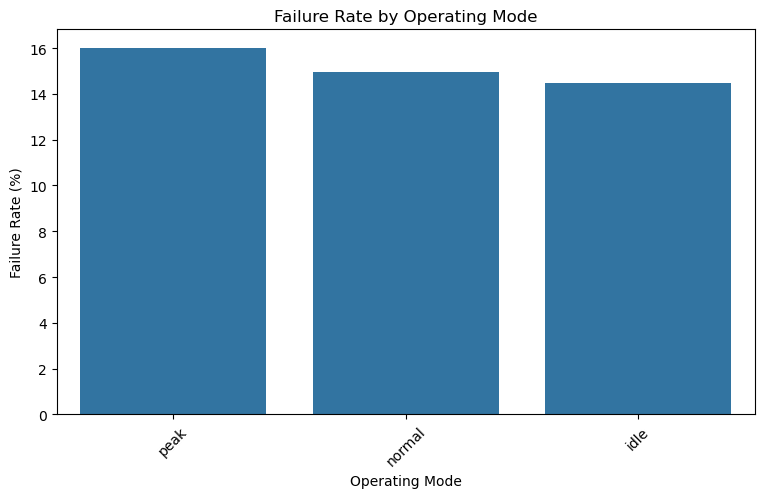

In [82]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=mode_failure_rate.index,
    y=mode_failure_rate.values
)

plt.title('Failure Rate by Operating Mode')
plt.xlabel('Operating Mode')
plt.ylabel('Failure Rate (%)')

plt.xticks(rotation=45)

plt.show()

# Find High-Risk Machines

In [83]:
machine_risk = (
    df.groupby('machine_id')
      .agg(
          Failure_Rate=('failure_within_24h', 'mean'),
          Avg_Vibration=('vibration_rms', 'mean'),
          Avg_Temperature=('temperature_motor', 'mean'),
          Avg_RUL=('rul_hours', 'mean'),
          Avg_Maintenance_Hours=('hours_since_maintenance', 'mean'),
          Avg_Repair_Cost=('estimated_repair_cost', 'mean')
      )
)

In [84]:
#Convert failure rate to percentage:

In [85]:
machine_risk['Failure_Rate'] = (
    machine_risk['Failure_Rate'] * 100
)

In [86]:
machine_risk.sort_values(
    'Failure_Rate',
    ascending=False
).head(10)

,Failure_Rate,Avg_Vibration,Avg_Temperature,Avg_RUL,Avg_Maintenance_Hours,Avg_Repair_Cost
machine_id,,,,,,
13,23.936614,1.973286,58.194625,33.031376,147.328198,0.0
10,23.464164,1.472722,52.657854,35.388951,104.881758,0.0
7,23.305085,1.558729,54.308983,35.644932,62.833729,0.0
4,23.049956,2.020351,56.507770,37.661849,76.470079,0.0
19,22.335891,0.946675,43.709118,39.011739,70.248363,0.0
20,20.510638,0.905779,41.397217,26.419064,119.345064,0.0
11,18.793706,2.015542,58.494410,32.093934,249.467561,0.0
1,15.687919,2.020696,54.288066,22.386904,145.430982,0.0
15,15.217391,1.990176,55.789870,25.895376,267.578269,0.0


**Create a Simple Risk Category**

In [87]:
def risk_level(rate):
    
    if rate >= 50:
        return 'High'
    elif rate >= 20:
        return 'Medium'
    else:
        return 'Low'

In [88]:
machine_risk['Risk_Level'] = (
    machine_risk['Failure_Rate']
    .apply(risk_level)
)

In [89]:
machine_risk['Risk_Level'].value_counts()

Risk_Level
Low       14
Medium     6
Name: count, dtype: int64

In [90]:
machine_risk.sort_values(
    'Failure_Rate',
    ascending=False
).head(10)

,Failure_Rate,Avg_Vibration,Avg_Temperature,Avg_RUL,Avg_Maintenance_Hours,Avg_Repair_Cost,Risk_Level
machine_id,,,,,,,
13,23.936614,1.973286,58.194625,33.031376,147.328198,0.0,Medium
10,23.464164,1.472722,52.657854,35.388951,104.881758,0.0,Medium
7,23.305085,1.558729,54.308983,35.644932,62.833729,0.0,Medium
4,23.049956,2.020351,56.507770,37.661849,76.470079,0.0,Medium
19,22.335891,0.946675,43.709118,39.011739,70.248363,0.0,Medium
20,20.510638,0.905779,41.397217,26.419064,119.345064,0.0,Medium
11,18.793706,2.015542,58.494410,32.093934,249.467561,0.0,Low
1,15.687919,2.020696,54.288066,22.386904,145.430982,0.0,Low
15,15.217391,1.990176,55.789870,25.895376,267.578269,0.0,Low


- I performed failure analysis by studying failure frequency, failure types, machine-type failure rates, operating-mode failure rates, and sensor behavior across failure and non-failure groups. I also analyzed estimated repair costs by failure type and created a machine-level risk table using failure rate, vibration, temperature, RUL, maintenance history, and repair cost. This helped identify machines that may require closer monitoring or maintenance attention.

# RUL & Maintenance Analysis

In [91]:
df['rul_hours'].mean()


np.float64(27.812510190499953)

In [92]:
df['rul_hours'].describe()

count    24042.000000
mean        27.812510
std         26.393801
min          0.500000
25%          0.500000
50%         22.570000
75%         46.410000
max         98.340000
Name: rul_hours, dtype: float64

In [93]:
#Compare RUL between machines that are expected to fail and those that aren't.
df.groupby('failure_within_24h')['rul_hours'].mean()

failure_within_24h
0    30.598986
1    11.780882
Name: rul_hours, dtype: float64

In [94]:
rul_failure = (
    df.groupby('failure_within_24h')
      .agg(
          Avg_RUL=('rul_hours', 'mean'),
          Min_RUL=('rul_hours', 'min'),
          Max_RUL=('rul_hours', 'max')
      )
)

rul_failure

,Avg_RUL,Min_RUL,Max_RUL
failure_within_24h,,,
0,30.598986,0.5,98.34
1,11.780882,0.5,23.99


In [95]:
#Visualize RUL vs Failure

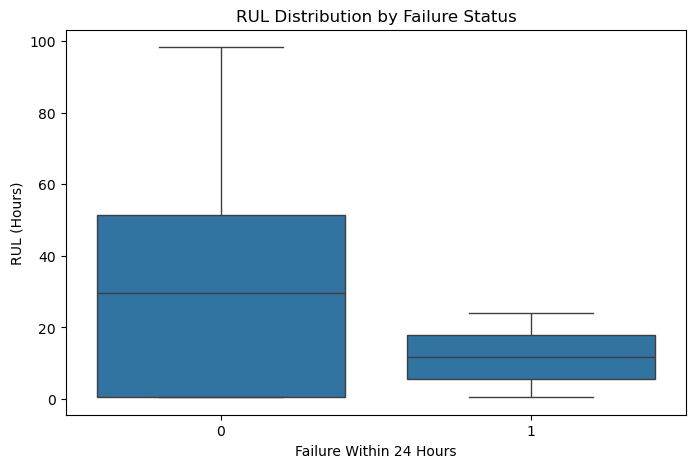

In [96]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='failure_within_24h',
    y='rul_hours'
)

plt.title('RUL Distribution by Failure Status')
plt.xlabel('Failure Within 24 Hours')
plt.ylabel('RUL (Hours)')

plt.show()

- Lower RUL is associated with increased near-term failure risk.

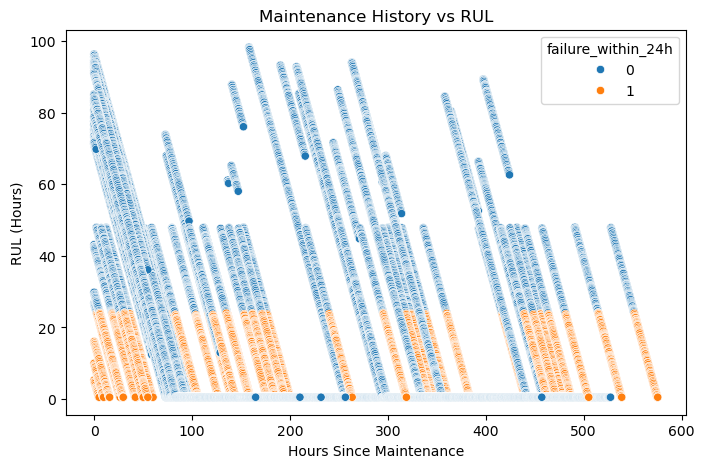

In [97]:
#Hours Since Maintenance vs RUL
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='hours_since_maintenance',
    y='rul_hours',
    hue='failure_within_24h'
)

plt.title('Maintenance History vs RUL')
plt.xlabel('Hours Since Maintenance')
plt.ylabel('RUL (Hours)')

plt.show()

In [98]:
# Calculate Correlation
df[ ['hours_since_maintenance', 'rul_hours']].corr()

,hours_since_maintenance,rul_hours
hours_since_maintenance,1.00000,-0.30679
rul_hours,-0.30679,1.00000


In [99]:
#Create RUL Categories
'''Critical → < 24 hours
Warning  → 24–72 hours
Healthy  → > 72 hours'''

'Critical → < 24 hours\nWarning  → 24–72 hours\nHealthy  → > 72 hours'

In [100]:
def rul_category(rul):
    
    if rul < 24:
        return 'Critical'
    elif rul <= 72:
        return 'Warning'
    else:
        return 'Healthy'

In [101]:
#apply
df['rul_category'] = df['rul_hours'].apply(rul_category)

In [102]:
#then check

In [103]:
df['rul_category'].value_counts()

rul_category
Critical    12356
Warning      9808
Healthy      1878
Name: count, dtype: int64

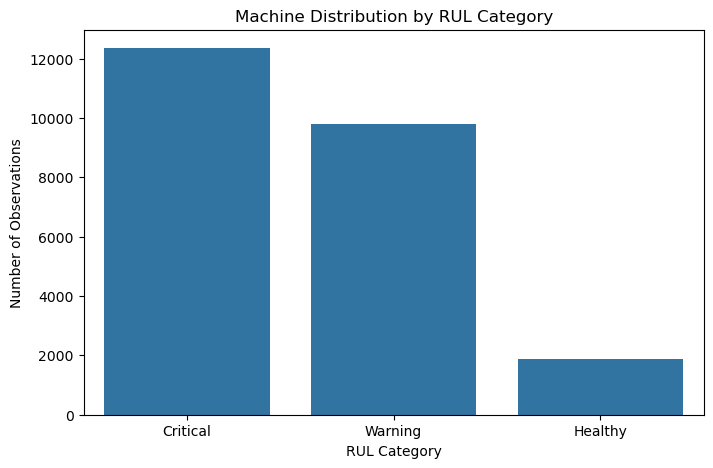

In [104]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='rul_category',
    order=['Critical', 'Warning', 'Healthy']
)

plt.title('Machine Distribution by RUL Category')
plt.xlabel('RUL Category')
plt.ylabel('Number of Observations')

plt.show()

- Business interpretation

- This tells the maintenance team how many observations fall into:

- Critical → immediate attention
- Warning → monitor / plan maintenance
- Healthy → normal condition

In [105]:
#Failure Rate by RUL Category
rul_failure_rate = (
    df.groupby('rul_category')['failure_within_24h']
      .mean()
      .mul(100)
      .reindex(['Critical', 'Warning', 'Healthy'])
)

rul_failure_rate

rul_category
Critical    28.811913
Warning      0.000000
Healthy      0.000000
Name: failure_within_24h, dtype: float64

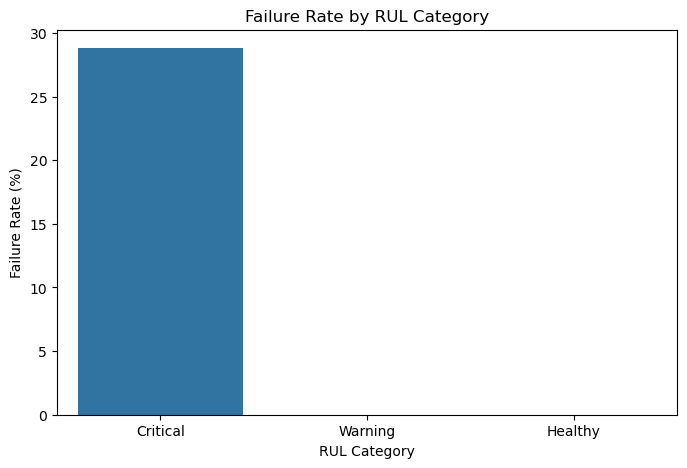

In [106]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=rul_failure_rate.index,
    y=rul_failure_rate.values
)

plt.title('Failure Rate by RUL Category')
plt.xlabel('RUL Category')
plt.ylabel('Failure Rate (%)')

plt.show()

In [107]:
# Maintenance Age Categories

bins = [0, 100, 200, 300, 400, np.inf]

labels = [
    '0-100',
    '100-200',
    '200-300',
    '300-400',
    '400+'
]

df['maintenance_age_group'] = pd.cut(
    df['hours_since_maintenance'],
    bins=bins,
    labels=labels,
    include_lowest=True
)

In [108]:
df['maintenance_age_group'].value_counts().sort_index()

maintenance_age_group
0-100      10834
100-200     4636
200-300     2733
300-400     3010
400+        2829
Name: count, dtype: int64

In [109]:
# Failure Rate by Maintenance Age


maintenance_failure_rate = (
    df.groupby(
        'maintenance_age_group',
        observed=True
    )['failure_within_24h']
    .mean()
    .mul(100)
)

maintenance_failure_rate

maintenance_age_group
0-100      12.571534
100-200    18.011217
200-300     4.354190
300-400    17.508306
400+       25.344645
Name: failure_within_24h, dtype: float64

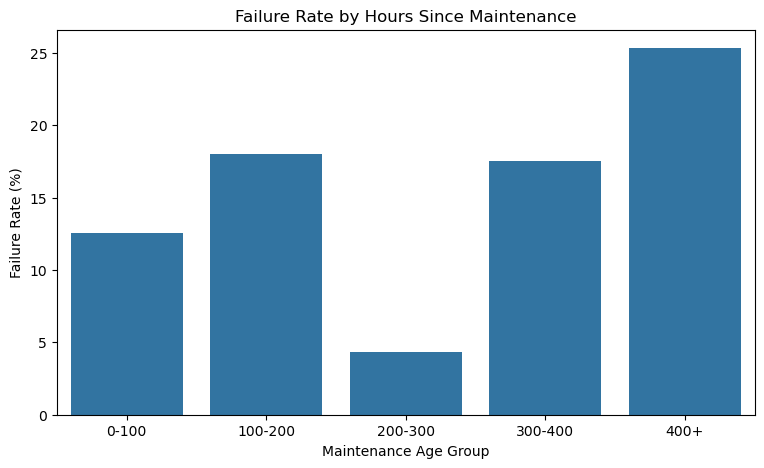

In [110]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=maintenance_failure_rate.index,
    y=maintenance_failure_rate.values
)

plt.title('Failure Rate by Hours Since Maintenance')
plt.xlabel('Maintenance Age Group')
plt.ylabel('Failure Rate (%)')

plt.show()

In [111]:
# Identify Critical Machines          combine RUL and failure status.
critical_machines = df[
    (df['rul_hours'] < 24) &
    (df['failure_within_24h'] == 1)
]


In [112]:
critical_machines.shape

(3560, 21)

In [113]:
critical_machines[
    [
        'machine_id',
        'machine_type',
        'rul_hours',
        'vibration_rms',
        'temperature_motor',
        'hours_since_maintenance',
        'failure_type'
    ]
].head(10)

,machine_id,machine_type,rul_hours,vibration_rms,temperature_motor,hours_since_maintenance,failure_type
191,1,CNC,23.74,2.93,62.83,325.12,hydraulic
192,1,CNC,23.41,0.90,51.15,325.45,hydraulic
193,1,CNC,23.29,1.02,52.34,325.57,hydraulic
194,1,CNC,22.79,1.14,54.62,326.07,hydraulic
195,1,CNC,22.66,0.99,51.23,326.20,hydraulic
196,1,CNC,22.26,1.01,53.07,326.60,hydraulic
197,1,CNC,22.19,1.08,52.26,326.67,hydraulic
198,1,CNC,21.98,1.27,52.37,326.88,hydraulic
199,1,CNC,21.78,0.93,54.63,327.08,hydraulic
200,1,CNC,21.69,0.97,50.90,327.17,hydraulic


In [114]:
# Create a Maintenance Priority
def maintenance_priority(row):

    if row['rul_hours'] < 24 and row['failure_within_24h'] == 1:
        return 'Immediate Attention'
    
    elif row['rul_hours'] <= 72:
        return 'Monitor'
    
    else:
        return 'Normal'

In [115]:
df['maintenance_priority'] = df.apply(
    maintenance_priority,
    axis=1
)

In [116]:
df['maintenance_priority'].value_counts()

maintenance_priority
Monitor                18604
Immediate Attention     3560
Normal                  1878
Name: count, dtype: int64

- I analyzed Remaining Useful Life in relation to maintenance history and failure status. I compared RUL between failure and non-failure observations, analyzed the relationship between hours since maintenance and RUL, and categorized machines into Critical, Warning, and Healthy groups using project-defined thresholds. I then calculated failure rates for each RUL and maintenance-age group and identified observations with low RUL and near-term failure risk for maintenance prioritization

# Sensor Correlation Analysis & Heatmap

In [117]:
#We want to find relationships such as:

#Vibration ↔ Temperature
#Vibration ↔ RPM
#Current ↔ Pressure
#Maintenance Hours ↔ RUL
#Sensor variables ↔ Failure

In [118]:
#Select relevant numerical columns
analysis_cols = [
    'vibration_rms',
    'temperature_motor',
    'current_phase_avg',
    'pressure_level',
    'rpm',
    'hours_since_maintenance',
    'ambient_temp',
    'rul_hours',
    'failure_within_24h',
    'estimated_repair_cost'
]

In [119]:
corr = df[analysis_cols].corr()

corr

,vibration_rms,temperature_motor,current_phase_avg,pressure_level,rpm,hours_since_maintenance,ambient_temp,rul_hours,failure_within_24h,estimated_repair_cost
vibration_rms,1.000000,0.744742,0.857972,0.764003,0.783552,0.013657,-0.003471,-0.044952,0.227189,NaN
temperature_motor,0.744742,1.000000,0.766447,0.694868,0.620717,0.027041,-0.003384,-0.074728,0.373780,NaN
current_phase_avg,0.857972,0.766447,1.000000,0.854898,0.779553,-0.001356,-0.005952,-0.023750,0.150483,NaN
pressure_level,0.764003,0.694868,0.854898,1.000000,0.610008,0.014721,-0.007994,0.021851,0.012593,NaN
rpm,0.783552,0.620717,0.779553,0.610008,1.000000,-0.075585,-0.008388,0.016983,-0.023057,NaN
hours_since_maintenance,0.013657,0.027041,-0.001356,0.014721,-0.075585,1.000000,0.010680,-0.306790,0.099519,NaN
ambient_temp,-0.003471,-0.003384,-0.005952,-0.007994,-0.008388,0.010680,1.000000,-0.004021,0.003907,NaN
rul_hours,-0.044952,-0.074728,-0.023750,0.021851,0.016983,-0.306790,-0.004021,1.000000,-0.253235,NaN
failure_within_24h,0.227189,0.373780,0.150483,0.012593,-0.023057,0.099519,0.003907,-0.253235,1.000000,NaN
estimated_repair_cost,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


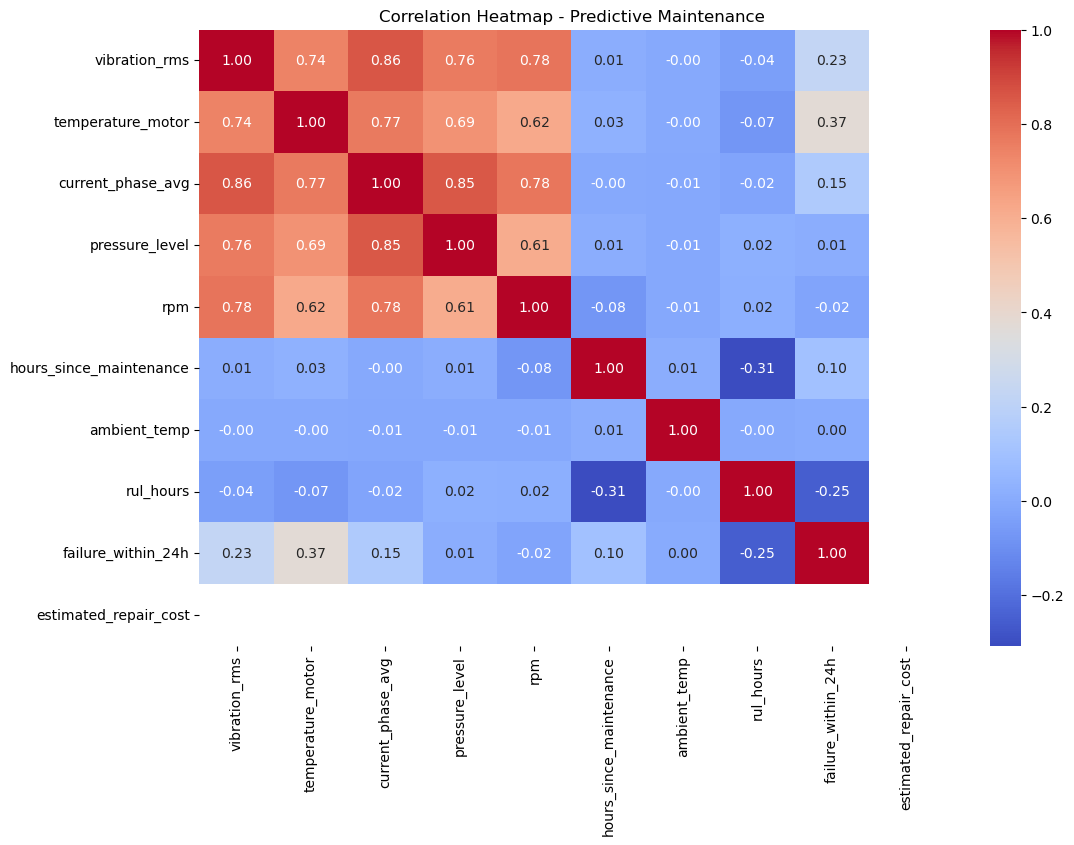

In [120]:
#create heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap - Predictive Maintenance')

plt.show()

In [121]:
#Find strongest relationships

corr_pairs = corr.unstack()

corr_pairs = corr_pairs[
    corr_pairs.index.get_level_values(0) !=
    corr_pairs.index.get_level_values(1)
]

corr_pairs.sort_values(
    ascending=False
).head(10)

current_phase_avg  vibration_rms        0.857972
vibration_rms      current_phase_avg    0.857972
pressure_level     current_phase_avg    0.854898
current_phase_avg  pressure_level       0.854898
vibration_rms      rpm                  0.783552
rpm                vibration_rms        0.783552
                   current_phase_avg    0.779553
current_phase_avg  rpm                  0.779553
temperature_motor  current_phase_avg    0.766447
current_phase_avg  temperature_motor    0.766447
dtype: float64

In [122]:
corr_matrix = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

corr_pairs = (
    corr_matrix
    .stack()
    .sort_values(ascending=False)
)

corr_pairs.head(10)

vibration_rms      current_phase_avg    0.857972
current_phase_avg  pressure_level       0.854898
vibration_rms      rpm                  0.783552
current_phase_avg  rpm                  0.779553
temperature_motor  current_phase_avg    0.766447
vibration_rms      pressure_level       0.764003
                   temperature_motor    0.744742
temperature_motor  pressure_level       0.694868
                   rpm                  0.620717
pressure_level     rpm                  0.610008
dtype: float64

In [123]:
# Find strongest positive relationships
corr_pairs.head(10)

vibration_rms      current_phase_avg    0.857972
current_phase_avg  pressure_level       0.854898
vibration_rms      rpm                  0.783552
current_phase_avg  rpm                  0.779553
temperature_motor  current_phase_avg    0.766447
vibration_rms      pressure_level       0.764003
                   temperature_motor    0.744742
temperature_motor  pressure_level       0.694868
                   rpm                  0.620717
pressure_level     rpm                  0.610008
dtype: float64

In [124]:
# Find strongest negative relationships
corr_pairs.tail(10)

current_phase_avg        ambient_temp              -0.005952
pressure_level           ambient_temp              -0.007994
rpm                      ambient_temp              -0.008388
                         failure_within_24h        -0.023057
current_phase_avg        rul_hours                 -0.023750
vibration_rms            rul_hours                 -0.044952
temperature_motor        rul_hours                 -0.074728
rpm                      hours_since_maintenance   -0.075585
rul_hours                failure_within_24h        -0.253235
hours_since_maintenance  rul_hours                 -0.306790
dtype: float64

In [125]:
rul_corr = (
    corr['rul_hours']
    .drop('rul_hours')
    .sort_values()
)

rul_corr

hours_since_maintenance   -0.306790
failure_within_24h        -0.253235
temperature_motor         -0.074728
vibration_rms             -0.044952
current_phase_avg         -0.023750
ambient_temp              -0.004021
rpm                        0.016983
pressure_level             0.021851
estimated_repair_cost           NaN
Name: rul_hours, dtype: float64

In [126]:
# specifically on failure
failure_corr = (
    corr['failure_within_24h']
    .drop('failure_within_24h')
    .sort_values()
)

failure_corr

rul_hours                 -0.253235
rpm                       -0.023057
ambient_temp               0.003907
pressure_level             0.012593
hours_since_maintenance    0.099519
current_phase_avg          0.150483
vibration_rms              0.227189
temperature_motor          0.373780
estimated_repair_cost           NaN
Name: failure_within_24h, dtype: float64

- Correlation analysis was performed to identify relationships among machine sensor parameters, maintenance history, RUL, failure status, and repair cost. The heatmap was used to identify strongly correlated variables and potential machine-health indicators. Variables showing meaningful relationships with RUL and failure status were selected for further investigation

# # Key Insights & Business Recommendations

## Key Insights

1. Motor temperature shows a positive association with failure within 24 hours.
2. Vibration also shows a positive association with failure risk.
3. Current phase average, vibration, pressure and RPM show strong positive correlations with each other.
4. Hours since maintenance has a negative relationship with RUL.
5. RUL has a negative association with failure within 24 hours.
6. Machine-level analysis helps identify machines that require higher maintenance attention.
7. Machines with lower RUL and higher failure rates should receive higher maintenance priority.

## Business Recommendations

1. Monitor motor temperature and vibration regularly because they show stronger associations with failure.
2. Give higher maintenance priority to machines with high failure rates and low RUL.
3. Use machine-level risk analysis to prioritize maintenance activities.
4. Track hours since maintenance to identify machines whose RUL may be declining.
5. Use sensor trends together rather than relying on a single sensor.
6. Use the analysis as a decision-support system for preventive maintenance.

In [127]:
final_machine_summary = (
    machine_risk
    .sort_values(
        ['Failure_Rate', 'Avg_RUL'],
        ascending=[False, True]
    )
    .head(10)
)

final_machine_summary

,Failure_Rate,Avg_Vibration,Avg_Temperature,Avg_RUL,Avg_Maintenance_Hours,Avg_Repair_Cost,Risk_Level
machine_id,,,,,,,
13,23.936614,1.973286,58.194625,33.031376,147.328198,0.0,Medium
10,23.464164,1.472722,52.657854,35.388951,104.881758,0.0,Medium
7,23.305085,1.558729,54.308983,35.644932,62.833729,0.0,Medium
4,23.049956,2.020351,56.507770,37.661849,76.470079,0.0,Medium
19,22.335891,0.946675,43.709118,39.011739,70.248363,0.0,Medium
20,20.510638,0.905779,41.397217,26.419064,119.345064,0.0,Medium
11,18.793706,2.015542,58.494410,32.093934,249.467561,0.0,Low
1,15.687919,2.020696,54.288066,22.386904,145.430982,0.0,Low
15,15.217391,1.990176,55.789870,25.895376,267.578269,0.0,Low
